# 03: Modelling walkthrough

The engines are `src/ml_models.py` and `src/dl_model.py`, and `src/final.py` is the only code that scores the test window. This notebook reads their saved outputs. The one exception is the gradient-descent demonstration, which fits on training rows only.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src import scratch
from src.evaluate import split_rows
from src.features import feature_columns, load_features
from src.ml_models import make_preprocessor
from src.utils import load_config

cfg = load_config()
REPORTS = Path("../reports")
metrics = json.loads((REPORTS / "final_metrics.json").read_text(encoding="utf-8"))

## Results against the PRD targets

In [2]:
display(pd.DataFrame(metrics["criteria"]).round(3))

,criterion,target,value,met
0,Volume MAPE <= 12%,12.000,8.545,True
1,Congestion macro-F1 >= 0.80,0.800,0.774,False
2,Accident ROC-AUC >= 0.75,0.750,0.643,False
3,Sequence model beats best classical on test RMSE,54.624,54.266,True
4,80% band covers 78-82% of test values,80.000,79.519,True
5,Batch inference for one horizon <= 30 s,30.000,4.590,True


## Gradient descent, written in NumPy

The PRD's build-it-once rule. The cost is J(w) = (1/n) ||Xw - y||^2, with gradient (2/n) X^T (Xw - y). Features are heavily collinear, so a fixed step like 0.1 diverges. The step comes from the largest eigenvalue of X^T X instead, which guarantees descent. The closed-form solution is the reference, and progress is slow along the small-eigenvalue directions that collinearity creates.

Training MSE: gradient descent 3598.8, normal equation 3481.7


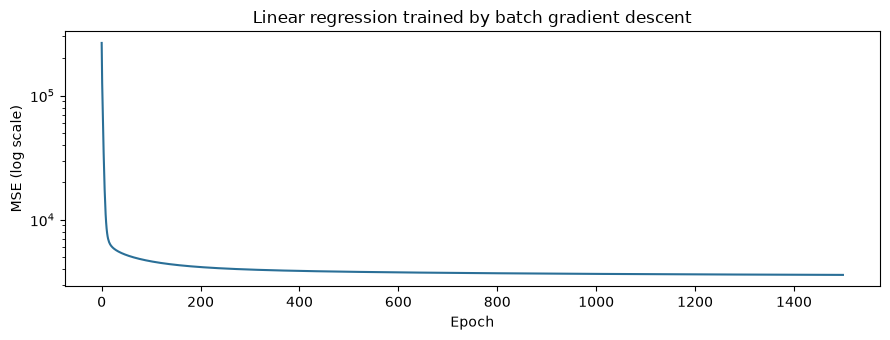

In [3]:
frame = load_features(1, cfg)
columns = feature_columns(frame)
train = split_rows(frame, "train")
X = make_preprocessor(columns).fit_transform(train[columns])
y = train["y_volume"].to_numpy()
weights, history = scratch.gradient_descent_lr(X, y, epochs=cfg["tuning"]["scratch_epochs"])
exact = scratch.normal_equation(X, y)
print(f"Training MSE: gradient descent {history[-1]:.1f}, normal equation {scratch.mse(y, scratch.predict_linear(X, exact)):.1f}")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(history, color="#2a6f97"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)"); ax.set_title("Linear regression trained by batch gradient descent")
fig.tight_layout(); fig.savefig(REPORTS / "figures" / "scratch_gradient_descent.png", dpi=120); plt.show()

## Scoreboards

Every model on the same rows. CV and validation scores drove the choices, and test scores are for the record.

In [4]:
for target, metric in [("volume", "rmse"), ("travel_time", "rmse"), ("speed", "rmse"), ("congestion", "macro_f1"), ("accident", "roc_auc")]:
    board = pd.read_csv(REPORTS / f"scoreboard_{target}.csv")
    keep = [c for c in ["model", "cv_mean", "cv_std", f"val_{metric}", f"test_{metric}", "infer_ms_per_1k"] if c in board]
    display(Markdown(f"**{target.replace('_', ' ').title()}**"), board[keep].round(4))

**Volume**

,model,cv_mean,cv_std,val_rmse,test_rmse,infer_ms_per_1k
0,Persistence (last window),NaN,NaN,101.9903,104.0908,NaN
1,Same window yesterday,NaN,NaN,138.8920,151.2380,NaN
2,Same window last week,NaN,NaN,123.0126,108.7287,NaN
3,Slot profile,NaN,NaN,75.5856,78.2068,NaN
4,linear_scratch,67.1926,13.4600,57.4121,59.2228,1.08
5,linear,68.2258,16.6207,56.3358,57.7937,1.34
6,tree,70.2185,21.1046,55.6140,56.0586,0.26
7,forest,64.6021,13.4591,54.9971,54.9336,2.25
8,xgboost,63.8512,13.3979,55.7216,54.6238,1.03
9,lstm,NaN,NaN,53.0940,54.2665,9.64


**Travel Time**

,model,cv_mean,cv_std,val_rmse,test_rmse,infer_ms_per_1k
0,linear,1.3519,0.0623,1.2442,1.3233,1.18
1,tree,1.1403,0.0982,1.1019,1.0632,0.32
2,forest,1.0887,0.0713,1.0430,1.0320,1.91
3,xgboost,1.0796,0.0664,1.0482,1.0311,0.68
4,derived_from_speed,NaN,NaN,1.0638,1.0853,3.29


**Speed**

,model,cv_mean,cv_std,val_rmse,test_rmse,infer_ms_per_1k
0,forest,3.785,0.5728,3.5742,3.4276,3.29


**Congestion**

,model,cv_mean,cv_std,val_macro_f1,test_macro_f1,infer_ms_per_1k
0,logistic,0.7391,0.0532,0.7508,0.7692,0.96
1,tree,0.7218,0.0555,0.7436,0.7548,0.38
2,forest,0.7478,0.0353,0.7573,0.7682,2.25
3,xgboost,0.7375,0.0448,0.7603,0.7672,5.37
4,svm_rbf,0.7227,0.0459,0.7465,0.7507,563.53
5,svm_linear,0.7175,0.0416,0.7345,0.7563,1.08
6,regress_then_band,0.7816,0.0000,0.7603,0.7717,2.25
7,regress_then_band_tuned,NaN,NaN,0.7643,0.7729,2.25


**Accident**

,model,cv_mean,cv_std,val_roc_auc,test_roc_auc,infer_ms_per_1k
0,logistic,0.6014,0.0178,0.5647,0.6428,1.33
1,tree,0.5995,0.0134,0.5490,0.6161,0.37
2,forest,0.5975,0.0140,0.5639,0.6196,1.94
3,xgboost,0.6137,0.0128,0.5495,0.6337,0.71
4,svm_rbf,0.5744,0.0223,0.5594,0.5923,2954.91
5,svm_linear,0.5912,0.0022,0.5632,0.6446,1.68


## Classical vs deep

# Classical vs deep benchmark

Generated by `python -m src.pipeline final`. Every row is scored on the same 26,869 test rows (9 to 31 May 2025, next-window volume, measured targets only). Models were chosen on validation before this table was computed.

| Model | Validation RMSE | Test RMSE | Test MAE | Test MAPE | Test R² |
|---|---:|---:|---:|---:|---:|
| Persistence (last window) | 101.99 | 104.09 | 71.50 | 16.32% | 0.8694 |
| Same window yesterday | 138.89 | 151.24 | 101.22 | 25.32% | 0.7244 |
| Same window last week | 123.01 | 108.73 | 70.38 | 17.87% | 0.8575 |
| Slot profile | 75.59 | 78.21 | 48.05 | 12.58% | 0.9263 |
| linear_scratch | 57.41 | 59.22 | 41.43 | 10.95% | 0.9577 |
| linear | 56.34 | 57.79 | 39.77 | 10.20% | 0.9597 |
| tree | 55.61 | 56.06 | 37.85 | 9.08% | 0.9621 |
| forest | 55.00 | 54.93 | 36.96 | 8.66% | 0.9636 |
| xgboost | 55.72 | 54.62 | 36.91 | 8.72% | 0.9640 |
| lstm | 53.09 | 54.27 | 36.56 | 8.55% | 0.9645 |
| gru | 53.27 | 54.28 | 36.65 | 8.66% | 0.9645 |
| bilstm | 53.28 | 54.19 | 36.51 | 8.55% | 0.9646 |
| lstm_multitask | 53.58 | 54.13 | 36.51 | 8.58% | 0.9647 |

**Verdict: the deep model did not clearly earn its added complexity.** The chosen LSTM scored a test RMSE of 54.27. That beats every classical model, so the PRD's benchmark is met. Against forest, the classical model chosen on validation (54.93), the gain is 0.67 vehicles per window, or 1.2%. The 95% interval for that gain, resampling whole test days, runs from 0.28 to 1.13, so it is measurably above zero. The best classical model on test was xgboost (54.62). A gain under 2% is counted here as too small to matter to operators, and the deep model costs 4.3x as much per prediction, needs its full window of history, and can't be read through a simple feature ranking. The LSTM, GRU and BiLSTM are all within 0.15 RMSE of each other, and accuracy barely falls from 30 to 120 minutes ahead, which suggests most of the remaining error is noise that no model can predict.


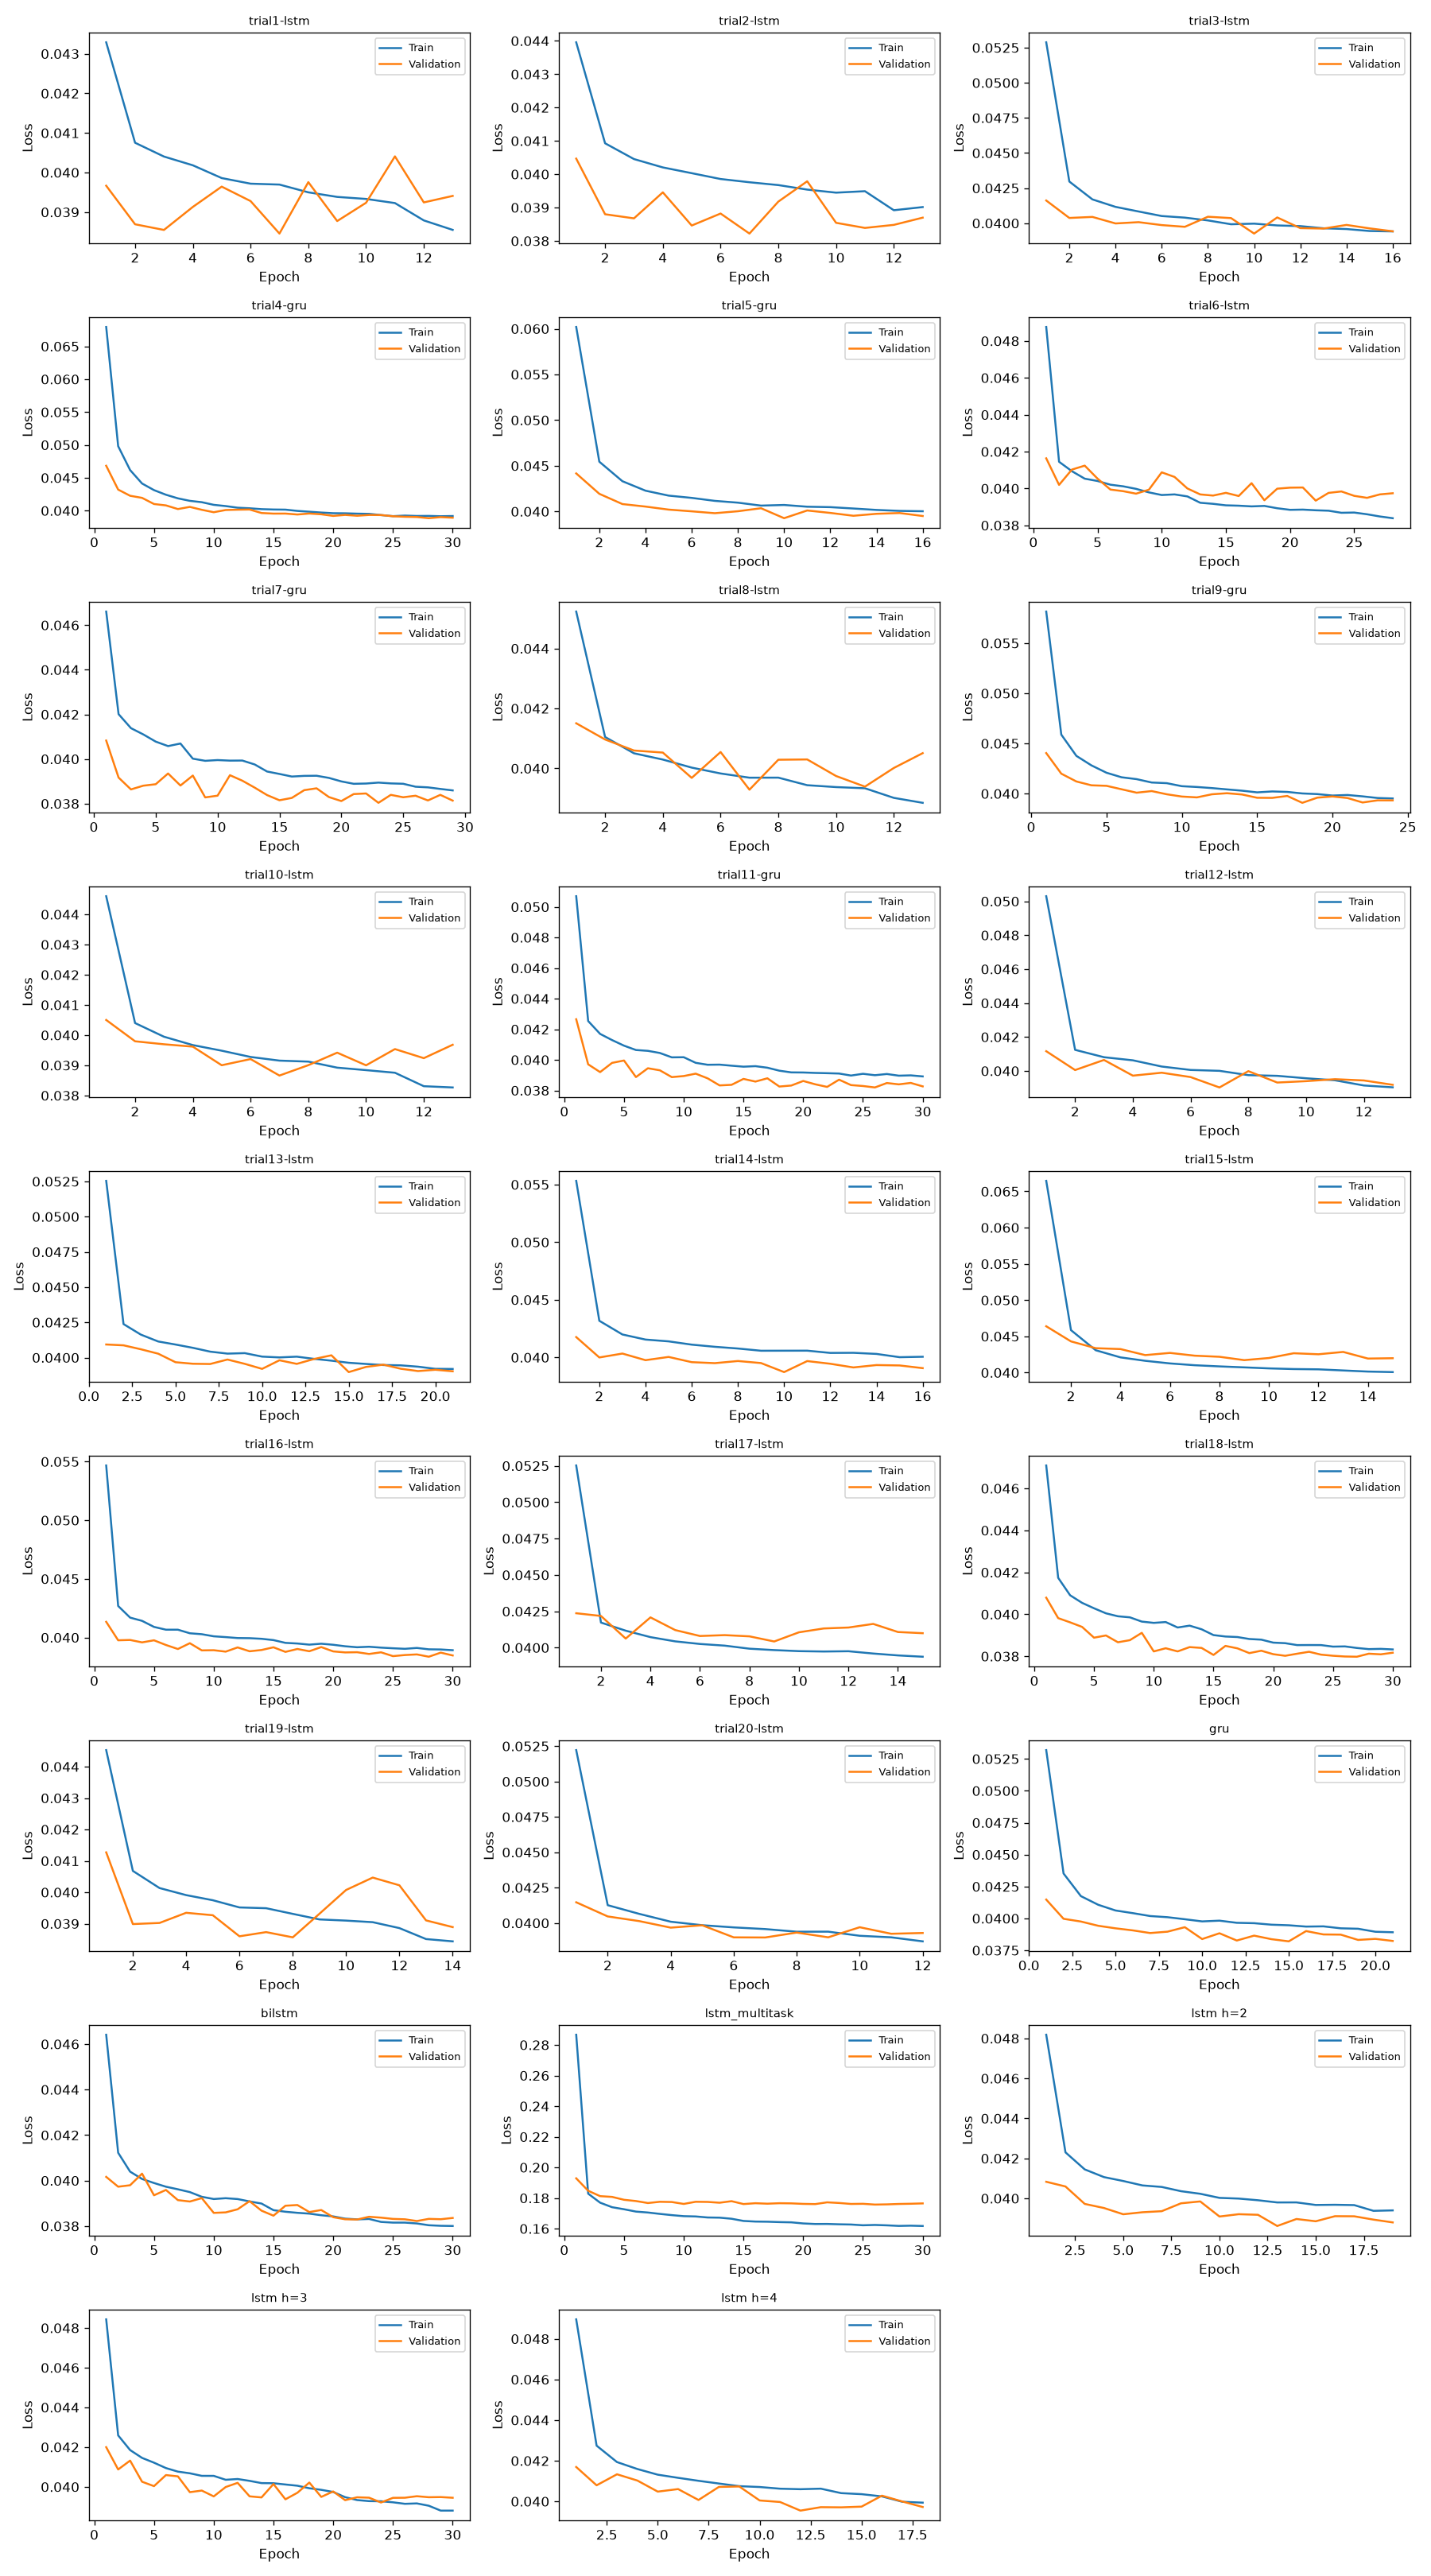

In [5]:
display(Markdown((REPORTS / "benchmark.md").read_text(encoding="utf-8")))
display(Image(REPORTS / "figures" / "deep_loss_curves.png"))

## Error analysis (PRD 13.3)

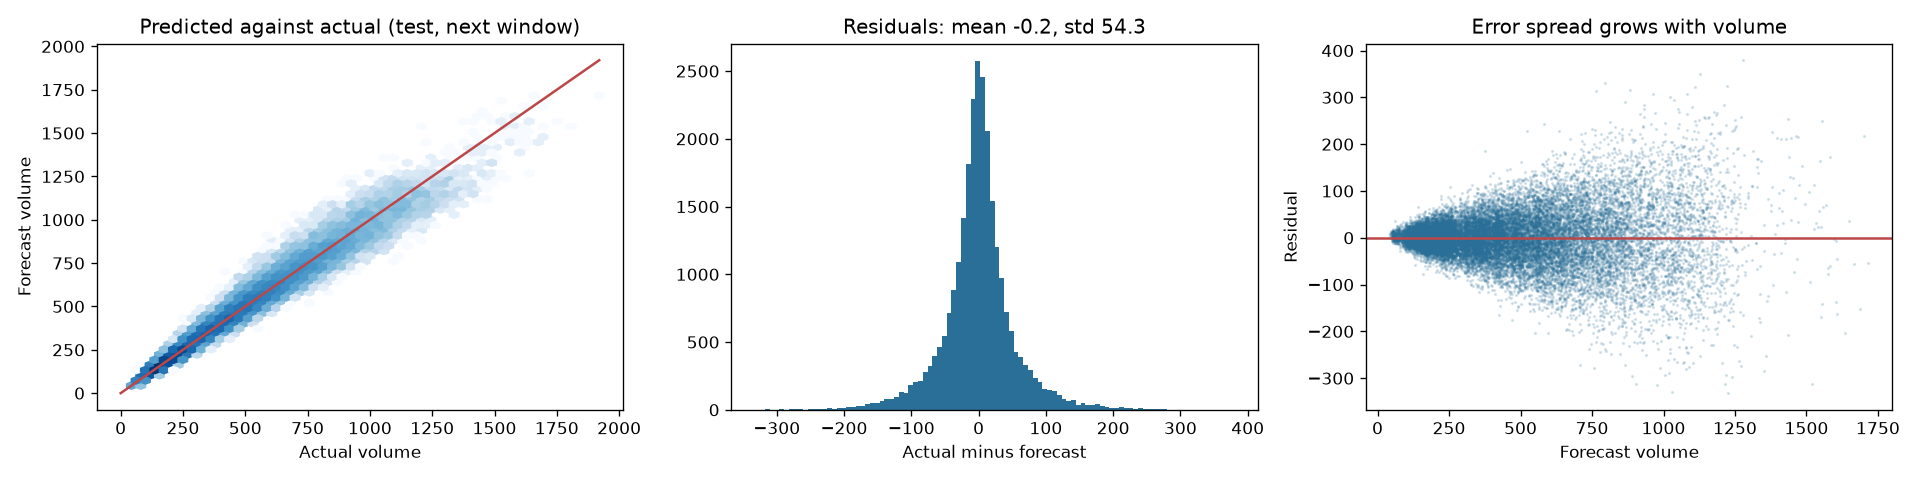

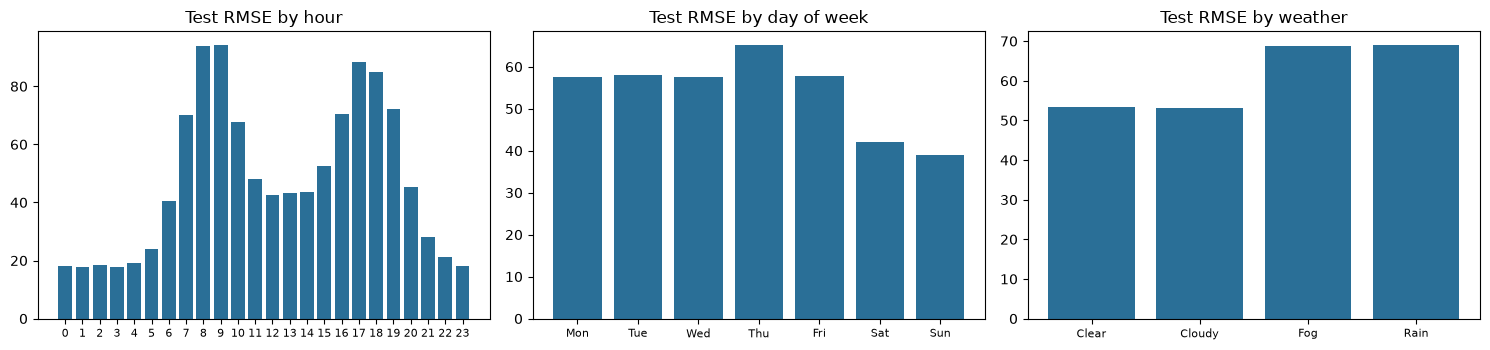

,Free-flow,Moderate,Heavy,Severe
Free-flow,15393,820,0,0
Moderate,399,5384,643,16
Heavy,0,341,1840,447
Severe,0,0,582,1004


In [6]:
display(Image(REPORTS / "figures" / "final_volume_residuals.png"))
errors = pd.read_csv(REPORTS / "error_breakdown_volume.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, group in zip(axes, ["hour", "day_of_week", "weather"]):
    part = errors[errors["group"] == group]
    if group == "hour":
        part = part.assign(value=part["value"].astype(int)).sort_values("value")
    if group == "day_of_week":
        part = part.set_index("value").reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).reset_index()
    ax.bar(part["value"].astype(str), part["rmse"], color="#2a6f97"); ax.set_title(f"Test RMSE by {group.replace('_', ' ')}"); ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); plt.show()
display(pd.read_csv(REPORTS / "confusion_congestion.csv", index_col=0))

## Accuracy by look-ahead, and whether the bands hold up

In [7]:
display(pd.read_csv(REPORTS / "metrics_by_horizon.csv").T.round(2))

,0,1,2,3
horizon,1.00,2.00,3.00,4.00
minutes_ahead,30.00,60.00,90.00,120.00
volume_rmse,54.27,54.72,55.30,55.33
volume_mape_pct,8.54,8.66,8.70,8.78
speed_rmse,3.43,3.45,3.46,3.47
speed_mape_pct,8.34,8.37,8.39,8.41
travel_time_rmse,1.03,1.03,1.04,1.04
travel_time_mape_pct,8.50,8.56,8.61,8.65
congestion_macro_f1,0.77,0.78,0.77,0.77
accident_roc_auc,0.64,0.62,0.62,0.60


## What the models rely on

In [8]:
display(pd.read_csv(REPORTS / "feature_importance_groups.csv").round(4))

,group,skill_change,target,metric
0,Usual level for the slot,233.2597,volume,RMSE increase
1,Recent volume,76.2826,volume,RMSE increase
2,Today against usual,9.2323,volume,RMSE increase
3,Calendar,7.7351,volume,RMSE increase
4,Clock,1.6775,volume,RMSE increase
5,Segment,1.5481,volume,RMSE increase
6,Recent speed,0.9206,volume,RMSE increase
7,Weather,0.4154,volume,RMSE increase
8,Mix and operations,-0.0428,volume,RMSE increase
9,Recent speed,0.0901,accident,AUC loss
